# Homework Reflection: Weeks 1-4

### Imports

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

### Datasets

In [45]:
df_1_1 = pd.read_csv('datasets/homework_1.1.csv')
df_1_2 = pd.read_csv('datasets/homework_1.2.csv')

df_4_1 = pd.read_csv('./datasets/homework_4.1.csv')
df_4_2 = pd.read_csv('./datasets/homework_4.2.b.csv')

### Homework Reflection 1

*1. In Coding Quiz 1, you are asked to find the distance of the farthest match in a set.  Is this farthest match distance too far to be a meaningful match?  How can you decide this?*

The distance of the farthest match in quiz_1 is `0.210217`. This number by itself doesn't mean much, but we can look at it relative to the dataset using standard deviation of the column. According to Peter Austin<sup>1</sup>, the optimal "caliper width" is "0.2 of the standard deviation". We can apply this to our dataset to find out if the farthest match value is too far to be meaningful:

In [18]:
treated = df_1_2[df_1_2['X'] == 1][['Z']].reset_index(drop=True)
control = df_1_2[df_1_2['X'] == 0][['Z']].reset_index(drop=True)

nn = NearestNeighbors(n_neighbors=1)
nn.fit(control[['Z']])

distances, indices = nn.kneighbors(treated[['Z']])

farthest_match = distances.max()

std_Z = df_2['Z'].std()
caliper = 0.2 * std_Z

print(f"Farthest Match: {farthest_match:.4f}")
print(f"Caliper: {caliper:.4f}")

Farthest Match: 0.2102
Caliper: 0.0580


As we can see, the farthest match is far from being within this caliper, meaning the distance is most likely too far to be meaningful.

*2. In Coding Quiz 1, there are two approaches to matching:*
*(A) Picking the best match X = 0 corresponding to each X = 1 using Z values.*
*(B) Using radius_neighbors to pick all matches X = 0 within a distance of 0.2 of each X = 1.*

*Invent your own type of matching similar to 1 and 2 (or look one up on the internet), which has a different way to pick the matches in X = 0.  Clearly explain the approach you invented or found.*

A way of matching besides the two we analyzed in Coding Quiz 1, could be creating a classification model trained on Z values with X being a categorical target column. After training this model, we could create *exact* matches, although this would only be as good as the model that was trained.

### Homework reflection 2

*1. Invent an example situation that would use fixed effects.*

An example situation that would use fixed effects is predicting how many of a specific item a chain of bakeries will sell in a given day. Perhaps there is a bakery in Times Square and another bakery in Oklahoma. The bakery in Times Square, by virtue of location, will sell much more items than the bakery in Oklahoma. Perhaps, there is a feature that causes a similar increase in sales across both stores however, such as temperature. Despite the sales data being drastically different, both locations could contribute to a model that predicts the amount of baked goods sold using temperature.

*2. Write a Python program that performs a bootstrap simulation to find the variance in the mean of the Pareto distribution when different samples are taken.  Explain what you had to do for this.  As you make the full sample size bigger (for the same distribution), what happens to the variance of the mean of the samples?  Does it stay about the same, get smaller, or get bigger?*

In [31]:
rng = np.random.default_rng(seed=42)

shape = 3.0      
scale = 10.0     
n_iterations = 5000

sample_sizes = [500, 1000, 2000, 4000, 8000]

results_list = []

for size in sample_sizes:
    original_sample = (rng.pareto(shape, size) + 1) * scale
    
    boot_means = np.empty(n_iterations)
    for i in range(n_iterations):
        boot_sample = rng.choice(original_sample, size=size, replace=True)
        boot_means[i] = boot_sample.mean()
        
    results_list.append({
        "Sample Size": size,
        "Sample Mean": original_sample.mean(),
        "Variance": boot_means.var()
    })

df_pareto = pd.DataFrame(results_list)

df_pareto

,Sample Size,Sample Mean,Variance
0,500,14.917188,0.100701
1,1000,14.678668,0.074653
2,2000,14.839501,0.023809
3,4000,15.121531,0.018528
4,8000,14.861846,0.006975


To find the variance in mean of the Pareto Distribution when different samples are taken, I had to select a random sample of the data and record the variances. To then answer how different sample sizes affected this variance, I had to create a separate loop where I incremented the amount of samples taken from the Pareto Distribution.

The variance decreases the more samples included. The Pareto distribution is heavily, positively, skewed. This means that with fewer samples, you will get larger values, but as you increase the sample size, you will gradually get smaller and smaller values. The distribution, due to the long tail, contains more of these smaller values, meaning as you expand the sample size you will get closer to the true mean resulting in a smaller and smaller variance.

### Homework reflection 3

*1. In the event study in Coding Quiz 3, how would we go about testing for a change in the second derivative as well?*

In Coding Quiz 3, we test for a change in the first derivative by splitting the dataset at our designated value, performing regression to find the slope (first derivative) both before and after split, and solving for the difference. To test for a change in the second derivate, we would simply have to use the formula generated by the linear model (using the slope and coefficients), solve the derivative for that formula, and then plug the pre-split and post-split values in and return the difference.

*2. Create your own scenario that illustrates differences-in-differences. Describe the story behind the data and show whether there is a nonzero treatment effect.*

A scenario that illustrates difference-in-differences could be students and their grades in a course that began to offer tutoring in the middle of the semester. If one group of students, group A, attended tutoring, and one group of students, group B, did *not* attend tutoring, we can examine whether or not tutoring actually had an effect.

If, for instance, after regressing for both groups, before and after tutoring was offered, we find that group A has a much larger slope that before tutoring was offered, while Group B has little difference in there slope, we can posit that tutoring had a positive outcome. If both groups show a nontrivial, positive difference perhaps the course material got easier or the professor changed his teaching style.

## Homework reflection 4

*1. The Coding Quiz gives two options for instrumental variables.  For the second item (dividing the range of W into multiple ranges), explain how you did it, show your code, and discuss any issues you encountered.*

For dividing the range of W into multiple ranges, I utilized Pandas `cut` function to create 25 discrete bins:

In [ ]:
n_bins = 25
df_4_1['W_bin'] = pd.cut(df_4_1['W'], bins=n_bins)

ratios = []
for wbin, g in df_4_1.groupby('W_bin', observed=True):
    z1 = g[g['Z'] == 1]
    z0 = g[g['Z'] == 0]

    # Issue Encountered
    if len(z1) == 0 or len(z0) == 0:
        continue

    y_diff = z1['Y'].mean() - z0['Y'].mean()
    x_diff = z1['X'].mean() - z0['X'].mean()

    ratios.append(y_diff / x_diff)

print(f"{np.mean(ratios):.1f}")

1.6


When originally iterating through by bin, I encountered an error where I was getting `NaN`. This was due to the fact that by binning, I created slices where there might not be complete representation for the instrument column. I could have tweaked the number of bins until I landed on a value that worked, but instead I just decided to include a check to make sure there was full representation and skip to the next iteration if not.

*2. Plot the college outcome (Y) vs. the test score (X) in a small range of test scores around 80. On the plot, compare it with the Y probability predicted by logistic regression. The ground truth Y value is 0 or 1; don't just plot 0 or 1 - that will make it unreadable.  Find some way to make it look better than that.*

/Users/ethanmarlatt/Desktop/OMDS/DX702/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


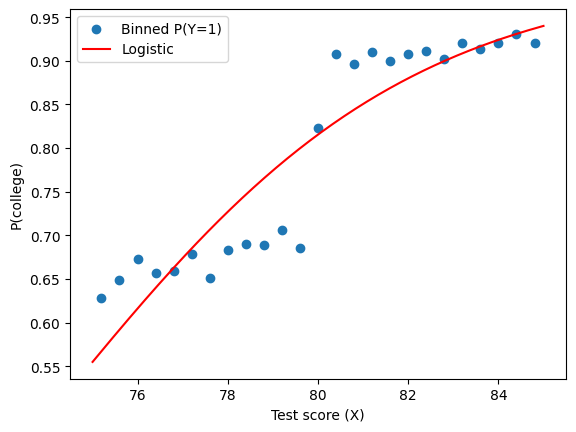

In [62]:
df_sub = df_4_2[(df_4_2['X2'] >= 75) & (df_4_2['X2'] <= 85)].copy()

n_bins = 25
df_sub['X_bin'] = pd.cut(df_sub['X2'], bins=n_bins)

x_means = []
y_means = []
for xbin, g in df_sub.groupby('X_bin', observed=True):
    if len(g) == 0:
        continue
    x_means.append(g['X2'].mean())
    y_means.append(g['Y2'].mean())
#print(x_means)
#print(y_means)

clf = LogisticRegression().fit(df_sub[['X2']], df_sub['Y2'])

x_grid = np.linspace(75, 85, 200).reshape(-1, 1)
p_hat = clf.predict_proba(x_grid)[:, 1]

plt.scatter(x_means, y_means, label='Binned P(Y=1)')
plt.plot(x_grid.ravel(), p_hat, 'r', label='Logistic')
plt.xlabel('Test score (X)')
plt.ylabel('P(college)')
plt.legend()
plt.show()

### Sources

1: Austin P. C. (2011). Optimal caliper widths for propensity-score matching when estimating differences in means and differences in proportions in observational studies. Pharmaceutical statistics, 10(2), 150–161. https://doi.org/10.1002/pst.433

## AI Appendix

**Prompt**
You said: create pareto distribution python

**Response (Gemini)**
```Python
import numpy as np

# Define parameters
shape = 3.0      # Alpha parameter (must be > 0)
scale = 10.0     # Minimum value (x_m)
size = 1000      # Number of samples

# Generate classical Pareto distribution samples
samples = (np.random.default_rng().pareto(shape, size) + 1) * scale
```

**Prompt**
Using the following code as a baseline: create a plot showing the binned probability as well as the logistic regression:
```python
df_sub = df_4_2[(df_4_2['X2'] >= 75) & (df_4_2['X2'] <= 85)].copy()

n_bins = 25
df_sub['X_bin'] = pd.cut(df_sub['X2'], bins=n_bins)

x_means = []
y_means = []
for xbin, g in df_sub.groupby('X_bin', observed=True):
    if len(g) == 0:
        continue
    x_means.append(g['X2'].mean())
    y_means.append(g['Y2'].mean())
#print(x_means)
#print(y_means)

clf = LogisticRegression().fit(df_sub[['X2']], df_sub['Y2'])
```

**Response (Claude)**
```python
import matplotlib.pyplot as plt

df_sub = df_4_2[(df_4_2['X2'] >= 75) & (df_4_2['X2'] <= 85)].copy()

n_bins = 25
df_sub['X_bin'] = pd.cut(df_sub['X2'], bins=n_bins)

x_means = []
y_means = []
for xbin, g in df_sub.groupby('X_bin', observed=True):
    if len(g) == 0:
        continue
    x_means.append(g['X2'].mean())
    y_means.append(g['Y2'].mean())
#print(x_means)
#print(y_means)

clf = LogisticRegression().fit(df_sub[['X2']], df_sub['Y2'])

x_grid = np.linspace(75, 85, 200).reshape(-1, 1)
p_hat = clf.predict_proba(x_grid)[:, 1]

# plot
plt.scatter(x_means, y_means, label='Binned P(Y=1)')
plt.plot(x_grid.ravel(), p_hat, 'r', label='Logistic')
plt.xlabel('Test score (X)')
plt.ylabel('P(college)')
plt.legend()
plt.show()
```